# Input DX Codes and Generate Base Files

This script creates the backbone of the dataset, which is to use DX code frequencies to generate a dataset with one observation per theoretical stay.  The constant OUTPUT_ROWS in 00_setup.py determines how many visits to generate.

In addition to the above, code reference tables are generated for the ICD-10 diagnoses and the CCS categories.

In [1]:
# Modify the file 00_setup.py to define input/output file paths on your system
from importlib.machinery import SourceFileLoader
setup = SourceFileLoader("setup", "./00_setup.py").load_module()

In [2]:
import pandas as pd
import numpy as np
import os
from pathlib import Path

In [3]:
import seaborn as sns
import random

In [4]:
import matplotlib.pyplot as plt

In [5]:
from sklearn.model_selection import train_test_split

## Import Data: ICD10 DX Frequencies

Actual 2023 code frequencies, which will be used to generate the visits

In [17]:
dx_freq_df = pd.read_csv(
        "./data/dx_freq.csv",
        na_values="*",
        header = 3,
        usecols=['ICD-10-CM Code',
                 'ICD-10-CM Code Description',
                 'CCSR for ICD-10-CM Category Default IP',
                 'CCSR Description',
                 '2023 NIS: Unweighted N for DX1 CCSR Default'],
        dtype='str'
    ) \
    .rename(columns={'ICD-10-CM Code':'icd10_cm_code', 
                     'ICD-10-CM Code Description':'icd10_cm_desc',
                     '2023 NIS: Unweighted N for DX1 CCSR Default':'visits',
                     'CCSR for ICD-10-CM Category Default IP':'ccsr_code',
                     'CCSR Description':'ccsr_desc'})
dx_freq_df = dx_freq_df[~dx_freq_df['icd10_cm_code'].isin(['Total', 'Missing', 'incn', 'invl'])]

In [18]:
dx_freq_df.shape

(75239, 5)

In [19]:
# Convert visits to count, include only codes with visits

In [20]:
dx_freq_df['visits'] = pd.to_numeric(dx_freq_df['visits'].str.strip() 
                            .str.replace(r'[\*,\,]', '', regex=True))

In [21]:
dx_freq_df['visits'].describe()

count      9103.000000
mean        736.485774
std        7261.472610
min          11.000000
25%          22.000000
50%          56.000000
75%         221.500000
max      449755.000000
Name: visits, dtype: float64

In [22]:
dx_freq_df.shape

(75239, 5)

In [23]:
dx_freq_df['visits'].sum()

np.float64(6704230.0)

In [24]:
dx_freq_df['visits'].isna().value_counts()

visits
True     66136
False     9103
Name: count, dtype: int64

We have ~9k codes which have significant volume (out of the ~75 k in the dataset).  The other 66k codes have no visits or only a handful (and are censored in the data).

I have the row count set to about 700 k.  This will be an average of 100 visits per code, but that will vary greatly.   The data is very skewed (mean far over the median)

<Axes: xlabel='visits'>

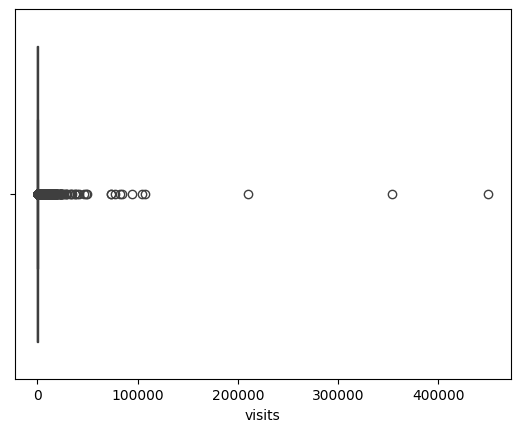

In [25]:
sns.boxplot(data=dx_freq_df, x="visits")

<Axes: ylabel='Frequency'>

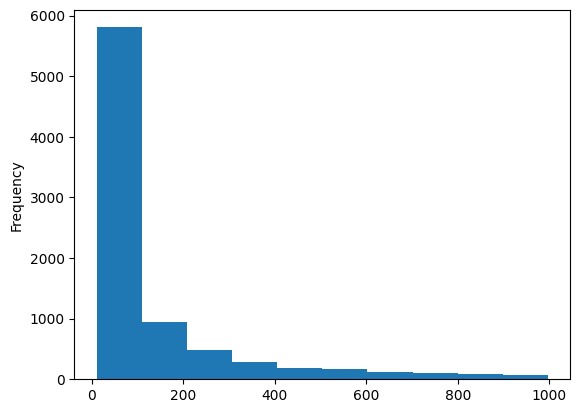

In [26]:
fig, ax = plt.subplots()
dx_freq_df[dx_freq_df['visits']<= 1000] \
    ['visits'].plot(kind='hist', ax=ax)

#### Restrict to used codes

In [27]:
dx_freq_selected = dx_freq_df[~dx_freq_df['visits'].isna()]

In [28]:
dx_freq_selected.sample(3)

,icd10_cm_code,icd10_cm_desc,ccsr_code,ccsr_desc,visits
28740,S22048A,S22048A: Other fracture of fourth thoracic ver...,INJ002,"INJ002 Fracture of the spine and back, initial...",49.0
16844,M7989,M7989: Other specified soft tissue disorders,MUS025,MUS025 Other specified connective tissue disease,274.0
2310,C9590,"C9590: Leukemia, unspecified not having achiev...",NEO064,NEO064 Leukemia - all other types,98.0


In [29]:
# Save the ICD code list with and without visits; we use the descriptions for refernence
# We save the visits column for later
dx_freq_selected.drop(columns='visits') \
    .to_csv(Path(setup.output_path).joinpath('REF_icd_cm_code.csv'), index=False)
dx_freq_selected.to_parquet(Path(setup.output_path).joinpath('01_ref_icd_cm_code.parquet'))

## CCSR code ref

Create a reference for the CCSR categories

In [30]:
ref_ccsr_df = dx_freq_selected.groupby('ccsr_code') \
    .agg({'ccsr_desc':'first',
          'icd10_cm_code':'count',
          'visits':'sum'}) \
    .reset_index() \
    .rename(columns={'icd10_cm_code':'icd10_cm_count'}) \
    .sort_values('ccsr_code')

In [31]:
ref_ccsr_df.shape

(441, 4)

In [32]:
ref_ccsr_df[['icd10_cm_count', 'visits']].describe()

,icd10_cm_count,visits
count,441.000000,441.000000
mean,20.641723,15202.335601
std,28.703634,47327.352937
min,1.000000,13.000000
25%,5.000000,632.000000
50%,12.000000,2782.000000
75%,25.000000,10147.000000
max,334.000000,684194.000000


The median of 12 ICD codes shows a lot of categories are fairly small.

In [33]:
ref_ccsr_df.sample(3)

,ccsr_code,ccsr_desc,icd10_cm_count,visits
400,RSP001,RSP001 Sinusitis,17,1155.0
69,DIG022,DIG022 Noninfectious gastroenteritis,11,22370.0
274,NEO009,NEO009 Head and neck cancers - tonsils,4,668.0


In [34]:
# Again - save 2 ways for a code reference and for stats
ref_ccsr_df \
     .drop(columns=['icd10_cm_count', 'visits']) \
     .to_csv(Path(setup.output_path).joinpath('REF_ccsr_code.csv'), index=False)
ref_ccsr_df.to_parquet(Path(setup.output_path).joinpath('01_ref_ccsr_code.parquet'))

## Base Dataset - Visits Drawn from Dist

Create a dataset with ICD code frequencies drawn from the distribution.  The number of visits to generate is in setup.OUTPUT_ROWS

In [35]:
print(f'Generating {setup.OUTPUT_ROWS} visits')

Generating 700000 visits


In [36]:
visits_df = dx_freq_selected[['icd10_cm_code', 'visits']] \
    .sample(n=setup.OUTPUT_ROWS, weights='visits', replace=True) \
    .drop(columns='visits')

In [37]:
visits_df.shape

(700000, 1)

In [38]:
visits_df.sample(3)

,icd10_cm_code
10748,J4542
264,A419
25814,S0266XB


In [39]:
# I will use this a lot
visits_len = len(visits_df)

## CCSR Code
Merge in the CCSR code.  This will be our hiearchical feature

In [40]:
visits_df = visits_df.merge(dx_freq_selected[['icd10_cm_code', 'ccsr_code']], 
                            how='left', on='icd10_cm_code')

In [41]:
visits_df['ccsr_code'].describe()

count     700000
unique       441
top       PNL001
freq       71466
Name: ccsr_code, dtype: object

## Import Stats for Other Features

##### Patient and visits

In [42]:
# Import the overall field summary from the public dataset
sum_stats =  pd.read_csv( "./data/sum_stats_overall.csv")

In [43]:
sum_stats['var'] = sum_stats['Variable / Label'].str.split(":").str[0]

In [44]:
sum_stats.sample(3)

,Variable / Label,N,Minimum,Maximum,Mean,Median,Sum,var
38,PRDAY11: Number of days from admission to 110_...,81599,-4,366,8.1,3,659010,PRDAY11
7,DISCWT: NIS discharge weight,6743716,5,5,5.0,5,33718585,DISCWT
39,PRDAY12: Number of days from admission to 110_...,63924,-4,366,9.0,4,577943,PRDAY12


##### Hospital related

In [45]:
hosp_stats_locteach =  pd.read_csv( "./data/hosp_locteach.csv")
hosp_stats_locteach

,HOSP_LOCTEACH,Frequency,Percent of Total
0,1: Rural,1594,38.12%
1,2: Urban nonteaching,932,22.29%
2,3: Urban teaching,1655,39.58%


In [46]:
cat_map = {'1: Rural':'Rural', '2: Urban nonteaching':'Urban_non',
           '3: Urban teaching':'Urban_teach'}

In [47]:
hosp_stats_locteach['category'] =  hosp_stats_locteach['HOSP_LOCTEACH'].apply(lambda x: cat_map[x])

In [48]:
hosp_stats_control =  pd.read_csv( "./data/hosp_control.csv")
hosp_stats_control

,Value,Label,Frequency,Percent_of_Total
0,1,"Government, non-federal (public)",805,19.25%
1,2,"Private, not-for-profit (voluntary)",2758,65.97%
2,3,"Private, investor-owned (proprietary)",618,14.78%


In [49]:
cat_map = {'Government, non-federal (public)':'Public', 
           'Private, not-for-profit (voluntary)':'Nonprofit',
           'Private, investor-owned (proprietary)':'For_profit'}

In [50]:
hosp_stats_control['category'] =  hosp_stats_control['Label'].apply(lambda x: cat_map[x])

##### Set the seed

In [51]:
rng = np.random.default_rng(23)

## Binary features

Set features according to their proportion in the AHRQ dataset.  In some cases, e.g. sex, this will be nonsense as the codes won't match the categories.

##### Function to set the variable

In [52]:
def get_binary_ser(var_name = 'FEMALE', 
                   rng=rng,
                   stats_df = sum_stats,
                   nrow = visits_len):
    var_rate= stats_df[stats_df['var'] == var_name]['Mean'].iloc[0]
    return pd.Series(rng.choice([0,1],
                                replace=True,
                                size = nrow,
                                p=[1-var_rate, var_rate]))

##### Set 'FEMALE'

In [53]:
sum_stats[sum_stats['Variable / Label'].str.contains('sex')]

,Variable / Label,N,Minimum,Maximum,Mean,Median,Sum,var
14,FEMALE: Indicator of sex,6742490,0,1,0.6,1,3726068,FEMALE


In [54]:
female_rate= sum_stats[sum_stats['var'] == 'FEMALE']['Mean'].iloc[0]
print(f"The patients are {female_rate:%} female")

The patients are 60.000000% female


In [55]:
visits_df['FEMALE'] = get_binary_ser()

In [56]:
visits_df['FEMALE'].value_counts(normalize=True)

FEMALE
1    0.59972
0    0.40028
Name: proportion, dtype: float64

##### Weekend status

In [57]:
rate= sum_stats[sum_stats['var'] == 'AWEEKEND']['Mean'].iloc[0]
print(f"The weekend rates is {rate:%}")

The weekend rates is 20.000000%


In [58]:
visits_df['AWEEKEND'] = get_binary_ser('AWEEKEND')
visits_df['AWEEKEND'].value_counts(normalize=True)

AWEEKEND
0    0.800206
1    0.199794
Name: proportion, dtype: float64

##### Elective indicator

In [59]:
rate= sum_stats[sum_stats['var'] == 'ELECTIVE']['Mean'].iloc[0]
print(f"The elective rates is {rate:%}")

The elective rates is 20.000000%


In [60]:
visits_df['ELECTIVE'] = get_binary_ser('ELECTIVE')
visits_df['ELECTIVE'].value_counts(normalize=True)

ELECTIVE
0    0.800113
1    0.199887
Name: proportion, dtype: float64

## One-Hot Features

Again use the public dataset descriptives to generate features - these are very low cardinality features that can be one hot encoded

In [61]:
def create_onehot(choice_ser, weight_ser,
                  feat_name = 'VAR',
                  rng = rng,
                  nrow = visits_len,
                  index = visits_df.index):
    p = (weight_ser / weight_ser.sum()).to_list()
    choice = pd.get_dummies(pd.Series(rng.choice(choice_ser, size = nrow, p=p)),
                           dtype='int', prefix=feat_name)
    
    if index is not None:
        choice.set_index(index, inplace=True)
    return choice
                  

In [62]:
control_df = create_onehot(hosp_stats_control['category'],
                                    hosp_stats_control['Frequency'],
                                    feat_name='HOSP_CONTROL')

In [63]:
control_df.shape

(700000, 3)

In [64]:
visits_df = pd.concat([visits_df,
                      create_onehot(hosp_stats_control['category'],
                                    hosp_stats_control['Frequency'],
                                    feat_name='HOSP_CONTROL')],
                      axis=1)

In [65]:
visits_df.sample(3)

,icd10_cm_code,ccsr_code,FEMALE,AWEEKEND,ELECTIVE,HOSP_CONTROL_For_profit,HOSP_CONTROL_Nonprofit,HOSP_CONTROL_Public
604440,O9832,PRG023,0,0,0,0,0,1
159921,I4891,CIR017,0,0,0,1,0,0
543426,T40601A,INJ022,0,0,0,1,0,0


In [66]:
visits_df['HOSP_CONTROL_Public'].mean()

np.float64(0.19255857142857144)

## LOS and Age

Estimate the distributions and calculate these features

#### Age

In [67]:
sum_stats[sum_stats['var'] == 'AGE']

,Variable / Label,N,Minimum,Maximum,Mean,Median,Sum,var
2,AGE: Age in years at admission,6743095,0,90,50.8,58,342406431,AGE


Mean is similar ish to the median.  I will do a normal dist.  with std about 20 years.  Note this will be nonsense for many cases - newborn codes, etc.

In [68]:
age_mean = sum_stats[sum_stats['var'] == 'AGE']['Mean'].iloc[0]
age_max = sum_stats[sum_stats['var'] == 'AGE']['Maximum'].iloc[0]

In [69]:
visits_df['AGE'] = rng.normal(loc=age_mean, scale=20, size=visits_len)

In [70]:
# Threshold to min and max
cond = [visits_df['AGE'] < 0, 
        visits_df['AGE'] > age_max]
choice = [0, age_max]
visits_df['AGE'] = np.select(cond, choice, visits_df['AGE'])

In [71]:
visits_df['AGE'].describe()

count    700000.000000
mean         50.660744
std          19.468113
min           0.000000
25%          37.312901
50%          50.805471
75%          64.317705
max          90.000000
Name: AGE, dtype: float64

<Axes: >

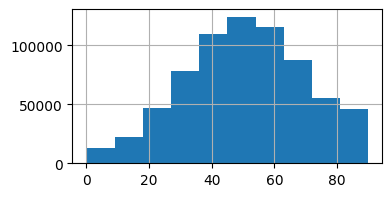

In [72]:
visits_df['AGE'].hist(figsize=(4,2))

#### LOS

I'm going to use a normal distribution centered at the median with a shortish std deviation for most, and a longer tail for some

In [73]:
sum_stats[sum_stats['var'] == 'LOS']

,Variable / Label,N,Minimum,Maximum,Mean,Median,Sum,var
23,LOS: Length of stay (cleaned),6741564,0,365,5.1,3,34149183,LOS


In [74]:
los_center = sum_stats[sum_stats['var'] == 'LOS']['Median'].iloc[0]
los_max = sum_stats[sum_stats['var'] == 'LOS']['Maximum'].iloc[0]
los_min = 1

In [75]:
# Split the index

In [76]:
norm_idx, exp_idx = train_test_split(visits_df.index, train_size=0.85)
print(f"{len(norm_idx)} shortish visits, {len(exp_idx)} extra long")

595000 shortish visits, 105000 extra long


Most cases: normally distributed but truncated / mostly short.  Truncate to 1. Use the median as the norm dist mean to keep it compact

In [77]:
los_norm = rng.normal(loc=los_center, scale=5, size=len(norm_idx))

In [78]:
cond = [los_norm < los_min,
        los_norm > los_max]
choice = [los_min, los_max]
los_norm_ser = pd.Series(np.select(cond, choice, los_norm),
                     index=norm_idx)

In [79]:
los_norm_ser.describe()

count    595000.000000
mean          4.146396
std           3.563931
min           1.000000
25%           1.000000
50%           2.997691
75%           6.365769
max          24.949462
dtype: float64

For the exponential cases, have a long tail

In [80]:
los_exp = rng.exponential(scale=(los_max/4), size=len(exp_idx))

In [81]:
cond = [los_exp < los_min,
        los_exp > los_max]
choice = [los_min, los_max]
los_exp_ser = pd.Series(np.select(cond, choice, los_exp),
                     index=exp_idx)

In [82]:
los_exp_ser.describe()

count    105000.000000
mean         89.770858
std          84.496261
min           1.000000
25%          26.484295
50%          63.124758
75%         127.014300
max         365.000000
dtype: float64

In [83]:
los_ser = pd.concat([los_norm_ser, los_exp_ser], axis=0) \
    .rename('LOS')

<Axes: >

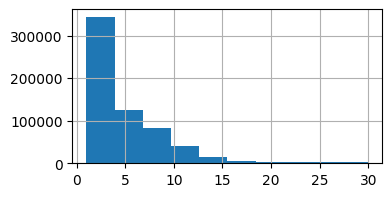

In [84]:
los_ser[los_ser < 30].hist(figsize=(4,2))

<Axes: >

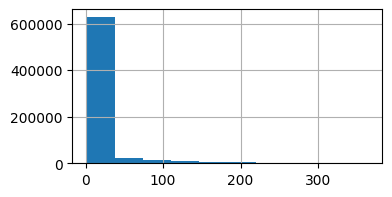

In [85]:
los_ser.hist(figsize=(4,2))

In [86]:
visits_df = pd.concat([visits_df.drop(columns='LOS', errors='ignore').sort_index(), 
                       los_ser.sort_index()], axis=1)

In [87]:
visits_df['LOS'].describe()

count    700000.000000
mean         16.990065
std          44.905503
min           1.000000
25%           1.000000
50%           4.014909
75%           8.545801
max         365.000000
Name: LOS, dtype: float64

## Save
We have our features!  Create a "visit ID" and save

In [88]:
visits_df.reset_index(inplace=True, names='VISIT_ID')
visits_df['VISIT_ID'] = visits_df['VISIT_ID'].astype('str').str.zfill(8)

In [91]:
visits_df.sample(3)

,VISIT_ID,icd10_cm_code,ccsr_code,FEMALE,AWEEKEND,ELECTIVE,HOSP_CONTROL_For_profit,HOSP_CONTROL_Nonprofit,HOSP_CONTROL_Public,AGE,LOS
442064,00442064,A419,INF002,1,0,0,1,0,0,42.055576,5.123786
18270,00018270,K648,DIG014,0,0,0,1,0,0,34.753859,5.193647
257096,00257096,A419,INF002,0,0,0,0,1,0,25.365491,1.000000


In [90]:
visits_df.to_parquet(Path(setup.output_path).joinpath('01_DATA_visits_features.parquet'))